# 0.0 Imports

In [20]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


from math import ceil
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, GroupKFold


# 0.1 Funções

# 0.2 Loading DataSet

In [2]:
df_raw = pd.read_excel('dataset/dataset_leite_fazenda_100_animais_900_dias.xlsx')

/home/lucas/.pyenv/versions/milk_env/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/lucas/.pyenv/versions/milk_env/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [3]:
#verificação shape do dataset
print(df_raw.shape)

#primeira cópia df_raw
df = df_raw.copy()

df.head(10).sort_values(by=['Date'], ascending=True).T

(6100, 49)


,0,1,2,3,4,5,6,7,8,9
Farm_ID,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001
Cattle_ID,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001
Date,2024-01-01 00:00:00,2024-01-16 00:00:00,2024-01-31 00:00:00,2024-02-15 00:00:00,2024-03-01 00:00:00,2024-03-16 00:00:00,2024-03-31 00:00:00,2024-04-15 00:00:00,2024-04-30 00:00:00,2024-05-15 00:00:00
Animal_Category,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow
Breed,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein
Country,BR,BR,BR,BR,BR,BR,BR,BR,BR,BR
State,MG,MG,MG,MG,MG,MG,MG,MG,MG,MG
Region,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast
Municipality,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa
Climate_Zone,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude


# 0.3 Baseline do Negócio

Quanto de CMS (Consumo de Matéria Seca) vai ser necessário para fornecer ao rebanho da fazenda nos próximos 180 dias.

boa previsão do leite -> boa previsão de consumo de MS -> investimento acertivo em volumoso -> economia de até 20% sobre o total da receita

CMS = (0,0185xPeso do animal) + (0,305xLitros do animal produzido)

In [4]:
# =================================================================
# Simulando da forma mais simples: CMS = peso_vivo * 0.03% parte 1
# =================================================================

"""
    Cada linha é uma coleta de dados no campo. Cada coleta são de 15 em 15 dias. 
    180 dias equivale a 12 observações em campo, ou 12 linhas do dataset.
"""

print('='*60)

#numero de animais
numero_de_vacas = df['Cattle_ID'].nunique()
print(f'Número de animais: {numero_de_vacas} vacas')

print('='*60)

#peso vivo dos animais por dia
peso_vivo_total_diario = df.groupby('Date')['Weight_kg'].sum()
print(f'Peso vivo total dos animais: {peso_vivo_total_diario:}kg')

print('='*60)

#rolling pega a linha 0 até a linha 11, ou seja, 12 datas/coletas
#peso vivo acumulado dos animais nos proximos 180 dias
peso_vivo_180d_total = peso_vivo_total_diario.rolling(12, min_periods=1).sum()
print(f'Peso vivo total acumulado dos animais dos proximos 180 dias somados: {peso_vivo_180d_total:}kg')

print('='*60)
#CMS de matéria seca diária (3% do PV)
CMS = df.groupby('Date')['Weight_kg'].sum()*0.03
print(f'Consumo de Matérica seca por peso vivo por dia: {CMS}kg')

print('='*60)

#Consumo de matéria seca acumulada nos proximos 180 dias
CMS_180d_total = CMS.rolling(12, min_periods=1).sum()
print(f'CMS acumulado dos proximos 180 dias somados: {CMS_180d_total:}kg')

print('='*60)

Número de animais: 100 vacas
Peso vivo total dos animais: Date
2024-01-01    59520.9
2024-01-16    59732.4
2024-01-31    59799.7
2024-02-15    59874.5
2024-03-01    59988.5
               ...   
2026-04-20    63254.3
2026-05-05    63192.5
2026-05-20    63150.9
2026-06-04    63277.7
2026-06-19    63212.8
Name: Weight_kg, Length: 61, dtype: float64kg
Peso vivo total acumulado dos animais dos proximos 180 dias somados: Date
2024-01-01     59520.9
2024-01-16    119253.3
2024-01-31    179053.0
2024-02-15    238927.5
2024-03-01    298916.0
                ...   
2026-04-20    759360.6
2026-05-05    759324.6
2026-05-20    759160.4
2026-06-04    759170.3
2026-06-19    759022.3
Name: Weight_kg, Length: 61, dtype: float64kg
Consumo de Matérica seca por peso vivo por dia: Date
2024-01-01    1785.627
2024-01-16    1791.972
2024-01-31    1793.991
2024-02-15    1796.235
2024-03-01    1799.655
                ...   
2026-04-20    1897.629
2026-05-05    1895.775
2026-05-20    1894.527
2026-06-04    18

In [5]:
# =================================================================
# Simulando da forma mais simples: CMS = peso_vivo * 0.03% parte 2
# =================================================================

#consumo de materia natural silagem proximos 180 dias (kg)
CMN_180d = CMS_180d_total / 0.3

#custo de materia natural silagem proximos 180 dias (R$/kg = 0,20 ) (R$)
custo_CMN_180d = CMN_180d * 0.2

#custo acumulado de materia natural silagem proximos 180 dias
custo_CMN_180d.sum()
print(f'custo com matéria natural nos próximos 180 dias é de R${custo_CMN_180d.sum():.2f}')

custo com matéria natural nos próximos 180 dias é de R$826651.44


# 1.0 Criando os Target e Pré-limpeza

In [6]:
print(df.isna().sum())
df.shape

df1 = df.copy()

#tirando as colunas que resolvemos não trabalhar
df1 = df1.drop(['Lag_Mean_180_Days', 'Target_Milk_15_Days', 'Target_Milk_30_Days', 'Target_Milk_90_Days', 
                'Farm_ID', 'Breed', 'Country', 'State', 'Region', 'Municipality', 'Management_System', 
                'Lot', 'Milking_Interval_hrs', 'Housing_Score', 'Grazing_Duration_hrs', 'Climate_Zone', 'Feed_Type', 'Lactation_Status'], axis=1)


Farm_ID                          0
Cattle_ID                        0
Date                             0
Animal_Category                  0
Breed                            0
Country                          0
State                            0
Region                           0
Municipality                     0
Climate_Zone                     0
Management_System                0
Feed_Type                        0
Season                           0
Age_Days                         0
Age_Months                       0
Weight_kg                        0
Parity                           0
Lactation_Status                 0
Lactation_Stage                  0
Days_in_Milk                     0
Days_Since_Calving               0
Lot                              0
Milking_Frequency_per_day        0
Milking_Interval_hrs             0
Body_Condition_Score             0
Body_Condition_Class             0
Ambient_Temperature_C            0
Humidity_percent                 0
Temperature_Humidity

In [7]:
#apagando as linhas que contém NaN 
df1 = df1.dropna(subset = ['Target_Milk_180_Days', 'Lag_Mean_90_Days'])

df1.shape

(4300, 31)

In [8]:
aux = df1.groupby('Cattle_ID')['Milk_Yield_L'].count()
aux

Cattle_ID
CATTLE_001    43
CATTLE_002    43
CATTLE_003    43
CATTLE_004    43
CATTLE_005    43
              ..
CATTLE_096    43
CATTLE_097    43
CATTLE_098    43
CATTLE_099    43
CATTLE_100    43
Name: Milk_Yield_L, Length: 100, dtype: int64

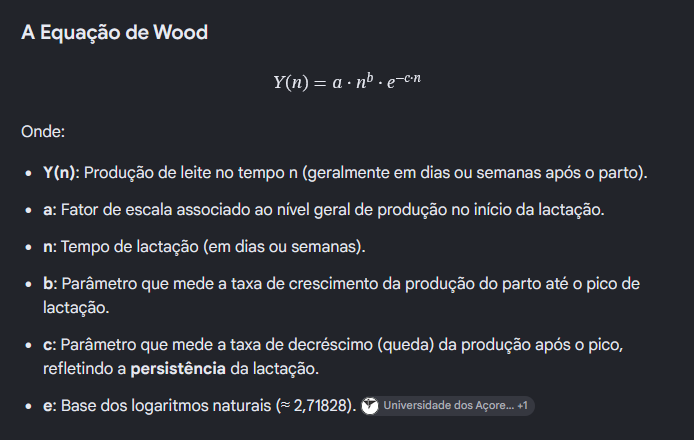

0-12 observações (TREINO)
13-24 (não posso usar)
25 - 30 (VAL) ->>>>> prever 42 <<<<<- 
31 - 36 (não posso usar)
37 - 43 (TESTE) ->>>> 55


10 dias de previsão

0-60 treino

71-80 val

85-100 teste

-----------                             produção real 20 Litros    target 75 = Milk_Yield_L 85            
 75 eu ja sei oq aconteceu no dia 85 -> meu treino ficou roubado
0-80 treino 

            MIlk_Yield_L: 20 litros
dia 85 -> produção real 20 Litros
85-100 teste ->> 95-110

# 2.0 Separação Treino, Test, Val e Target

In [9]:
#garantindo que as colunas sejam datas
df1['Date'].info()

#lista as datas distintas, em ordem
registros = df1['Date'].sort_values().unique()
registros

#os ultimos o primeiro registro do grupo de dados test, de trás pra frente
registros_test = registros[-7]
registros_test

X_train = df1.loc[(df1['Date'] < registros_test), :].copy()

X_test = df1.loc[(df1['Date'] >= registros_test), :].copy()

#treino e teste separados, ainda falta val e tirar as interseções

#=======================================================================================

#separando treino e val
aux_1 = X_train['Date'].sort_values().unique()
registros_train = aux_1[11]

X_val = X_train.loc[(X_train['Date'] > registros_train), :].reset_index(drop=True)

X_train = X_train.loc[(X_train['Date'] <= registros_train), :].reset_index(drop=True)

#=======================================================================================

#tirando um pedaço do inicio de val (12 posições) e um pedaço do final de val (6)
aux_2 = X_val['Date'].sort_values().unique()
registros_val = aux_2[11]

X_val = X_val.loc[(X_val['Date'] > registros_val), :].reset_index(drop=True)


aux_3 = X_val['Date'].sort_values().unique()
registros_val_2 = aux_3[-6]

X_val = X_val.loc[(X_val['Date'] < registros_val_2), :].reset_index(drop=True)

X_val['Date'].nunique()

<class 'pandas.Series'>
Index: 4300 entries, 6 to 6087
Series name: Date
Non-Null Count  Dtype         
--------------  -----         
4300 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 67.2 KB


6

In [10]:
#separando X de y

y_train = X_train['Target_Milk_180_Days']
X_train = X_train.drop('Target_Milk_180_Days', axis=1)

y_test = X_test['Target_Milk_180_Days']
X_test = X_test.drop('Target_Milk_180_Days', axis=1)

y_val = X_val['Target_Milk_180_Days']
X_val = X_val.drop('Target_Milk_180_Days', axis=1)

In [11]:
#verificando se as divisões foram corretas em relação a dimensão

print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

print(X_val.shape)
print(y_val.shape)

(1200, 30)
(1200,)
(700, 30)
(700,)
(600, 30)
(600,)


In [12]:
#concantenando x e y train para fazer E.D.A

df_train = pd.concat([X_train, y_train], axis=1)

# 3.0 Analisando os Dados

In [13]:
#conferindo celulas vazias e duplicadas
print(df_train.isna().sum())
print(df_train.shape)
print(df_train.duplicated().sum())

Cattle_ID                     0
Date                          0
Animal_Category               0
Season                        0
Age_Days                      0
Age_Months                    0
Weight_kg                     0
Parity                        0
Lactation_Stage               0
Days_in_Milk                  0
Days_Since_Calving            0
Milking_Frequency_per_day     0
Body_Condition_Score          0
Body_Condition_Class          0
Ambient_Temperature_C         0
Humidity_percent              0
Temperature_Humidity_Index    0
Heat_Stress_Class             0
Health_Status                 0
Days_Since_Health_Event       0
Rumination_Time_hrs           0
Resting_Hours                 0
Water_Intake_L                0
Walking_Distance_km           0
Previous_Week_Avg_Yield       0
Milk_Yield_L                  0
Dry_Matter_Intake_kg          0
Lag_Mean_15_Days              0
Lag_Mean_30_Days              0
Lag_Mean_90_Days              0
Target_Milk_180_Days          0
dtype: i

# 4.0 Análise Descritiva

## 4.1 Variáveis Numéricas

In [14]:
#separando os dados numéricos
num_atributos = df_train.select_dtypes(include=['float64', 'int'])
num_atributos.T

,0,1,2,3,4,5,6,7,8,9,...,1190,1191,1192,1193,1194,1195,1196,1197,1198,1199
Age_Days,1097.00,1112.00,1127.00,1142.00,1157.00,1172.00,1187.00,1202.00,1217.00,1232.00,...,352.00,367.00,382.00,397.00,412.00,427.00,442.00,457.00,472.00,487.00
Age_Months,36.00,36.50,37.00,37.50,38.00,38.50,39.00,39.50,40.00,40.50,...,11.60,12.10,12.60,13.00,13.50,14.00,14.50,15.00,15.50,16.00
Weight_kg,619.60,617.90,619.00,628.30,624.50,629.60,619.10,620.20,604.00,593.00,...,371.80,365.00,377.60,389.70,392.50,401.80,406.80,418.90,434.50,435.20
Parity,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,2.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Days_in_Milk,260.00,275.00,290.00,0.00,0.00,0.00,0.00,0.00,15.00,30.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Days_Since_Calving,260.00,275.00,290.00,305.00,320.00,335.00,350.00,365.00,15.00,30.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Milking_Frequency_per_day,3.00,3.00,3.00,0.00,0.00,0.00,0.00,0.00,3.00,3.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Body_Condition_Score,3.44,3.76,3.67,3.37,3.40,3.27,3.68,3.55,3.15,3.20,...,3.42,3.23,3.42,3.34,3.33,3.28,3.29,3.28,3.40,3.35
Ambient_Temperature_C,23.72,23.97,22.70,24.29,24.62,22.96,21.57,22.16,18.23,20.42,...,22.70,24.29,24.62,22.96,21.57,22.16,18.23,20.42,17.81,17.47
Humidity_percent,76.05,89.44,84.96,78.67,77.74,76.08,73.65,71.80,75.67,66.70,...,84.96,78.67,77.74,76.08,73.65,71.80,75.67,66.70,69.08,70.70


In [15]:
#tendencia central - média e mediana

ct1 = pd.DataFrame(num_atributos.mean()).T

ct2 = pd.DataFrame(num_atributos.median()).T

#dispersão: std, minimo, maximo, range, skewness, kurtosis

d1 = pd.DataFrame(num_atributos.std()).T
d2 = pd.DataFrame(num_atributos.min()).T
d3 = pd.DataFrame(num_atributos.max()).T
d4 = pd.DataFrame(num_atributos.max() - num_atributos.min()).T
d5 = pd.DataFrame(num_atributos.skew()).T
d6 = pd.DataFrame(num_atributos.kurtosis()).T

#concatenar os resultados
m = pd.concat([ct1, ct2, d1, d2, d3, d4, d5, d6], axis=0).T.reset_index()

#trocando nome das colunas
m.columns = ['atributos', 'mean', 'median', 'std', 'min', 'max', 'range', 'skew', 'kurtosis']
m.style.background_gradient(cmap='Blues')

#skew:
#-0.5 a 0.5: pouco assimetria
#-1 a -0,5: assimetrica moderadamente
#0.5 a 1: assimetrica moderadamente
#-1 < e > 1: assimetria forte

,atributos,mean,median,std,min,max,range,skew,kurtosis
0,Age_Days,1634.560000,1651.500000,660.429087,282.000000,2797.000000,2515.000000,-0.192298,-0.843483
1,Age_Months,53.702250,54.250000,21.697672,9.300000,91.900000,82.600000,-0.192437,-0.843509
2,Weight_kg,607.372417,628.250000,81.556840,327.400000,738.300000,410.900000,-1.235916,1.308511
3,Parity,2.443333,3.000000,1.423075,0.000000,5.000000,5.000000,-0.191321,-0.770640
4,Days_in_Milk,97.397500,71.000000,97.302086,0.000000,300.000000,300.000000,0.598008,-1.013171
5,Days_Since_Calving,151.042500,135.000000,118.719372,0.000000,365.000000,365.000000,0.261187,-1.297977
6,Milking_Frequency_per_day,1.750833,2.000000,1.214487,0.000000,3.000000,3.000000,-0.513228,-1.325061
7,Body_Condition_Score,3.353250,3.380000,0.236980,2.630000,4.010000,1.380000,-0.247915,-0.445687
8,Ambient_Temperature_C,21.660000,22.430000,2.483792,17.470000,24.620000,7.150000,-0.568358,-1.148973
9,Humidity_percent,75.878333,75.860000,6.171315,66.700000,89.440000,22.740000,0.698921,-0.062933


## 4.2 Variáveis Categóricas

In [16]:
cat_atributos = df_train.select_dtypes(exclude=['float64', 'int', 'datetime64'])

print(cat_atributos.columns)
print(cat_atributos.nunique())
cat_atributos.T

Index(['Cattle_ID', 'Animal_Category', 'Season', 'Lactation_Stage',
       'Body_Condition_Class', 'Heat_Stress_Class', 'Health_Status'],
      dtype='str')
Cattle_ID               100
Animal_Category           2
Season                    3
Lactation_Stage           5
Body_Condition_Class      3
Heat_Stress_Class         3
Health_Status             4
dtype: int64


,0,1,2,3,4,5,6,7,8,9,...,1190,1191,1192,1193,1194,1195,1196,1197,1198,1199
Cattle_ID,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,...,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100
Animal_Category,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,...,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer
Season,Autumn,Autumn,Autumn,Autumn,Autumn,Winter,Winter,Winter,Winter,Winter,...,Autumn,Autumn,Autumn,Winter,Winter,Winter,Winter,Winter,Winter,Spring
Lactation_Stage,Late,Late,Late,Dry,Dry,Dry,Dry,Dry,Early,Early,...,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation
Body_Condition_Class,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok,...,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok
Heat_Stress_Class,Moderate,Moderate,Mild,Moderate,Moderate,Mild,Mild,Mild,No_Stress,No_Stress,...,Mild,Moderate,Moderate,Mild,Mild,Mild,No_Stress,No_Stress,No_Stress,No_Stress
Health_Status,Healthy,Healthy,Healthy,Healthy,Lameness,Lameness,Healthy,Healthy,Healthy,Healthy,...,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy


## 4.3 Hipóteses

1. Vacas com estágio de lactação médio tem maior produtividade diários que vacas com estágio cedo e tardio
2. Vacas com idade mediana produz mais leite que as demais faixas de idade
3. Vacas mais pesadas tendem a produzir mais leite
4. Vacas com número de partos mediano produz mais leite que as demais faixas de numero de partos
5. Vacas que ingerem mais águas produzem mais litros leite diários
6. Vacas que andam mais, produzem menos litros de leite diários
7. Vacas que descansam mais tem mais produtividade litros de leite diários
8. Vacas no outono produzem mais litros de leite diariamente
9. Na maior parte das vezes, vacas com média diária da semana anterior com maiores produtividades, tendem a produzir maior litros de leite
10. Vacas com score corporal 3 tendem a ter maior produtividade diária
11. Vacas com intervalo de ordenha de 8h tendem a ter maior produtividade diária
12. Vacas saudáveis tendem a produzir mais litros de leite 

# 5.0 Análise Exploratória de Dados (E.D.A)

## 5.1 Análise Univariada

### 5.1.1 Análise Variável Resposta

<Axes: xlabel='Target_Milk_180_Days', ylabel='Count'>

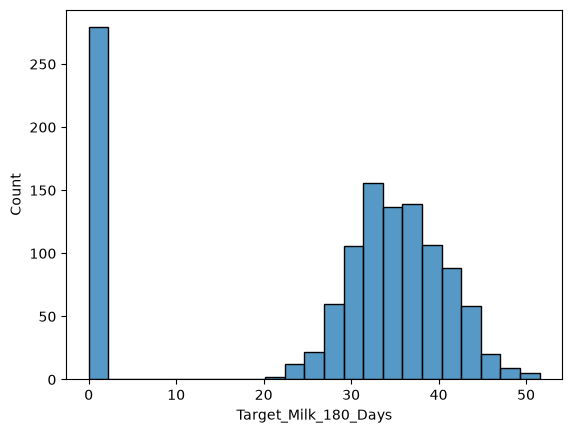

In [17]:
#analisando a variavel resposta

sns.histplot(data=df_train, x='Target_Milk_180_Days')

### 5.1.2 Análise Univariada Numéricas

## Bloco 1 — Importações e configuração

- **`TARGET`**: a coluna que se quer prever.
- **`GRUPO`**: a coluna que identifica cada vaca. Usada para separar a validação cruzada por animal.
- **`num_cols`**: as colunas numéricas, **sem o alvo**. Como o alvo é numérico, sem o `if c != TARGET` ele entraria na lista e seria comparado consigo mesmo. `Cattle_ID` é texto, então já fica de fora.
- **`GroupKFold(n_splits=5)`**: divide os dados em 5 partes, garantindo que **todas as linhas de uma vaca fiquem na mesma parte**.
- **`arvore`**: a árvore que mede relações curvas. Está aqui fora do loop porque a configuração é a mesma para todas as features.
    - **`max_depth=3`**: no máximo 3 níveis de perguntas, o que dá até 8 faixas.
    - **`min_samples_leaf=20`**: cada faixa precisa de pelo menos 20 linhas, para a árvore não criar faixas para pontos isolados.

> **Por que separar por vaca.** Cada vaca aparece em várias linhas (uma por coleta). Com um `KFold` comum, linhas da mesma vaca caem no treino e no teste ao mesmo tempo, e a árvore "reconhece" a vaca em vez de aprender a relação. É como uma prova com questões que o aluno já viu na lista de exercícios: a nota sobe, mas não mede o aprendizado. Com `GroupKFold`, a árvore é testada em vacas que ela nunca viu.


## Bloco 2 — O loop: calcular as métricas de cada feature

- **`dados = ...dropna()`**: pega a feature, o alvo e o ID da vaca, e remove a linha inteira se faltar qualquer um. Assim as três colunas ficam alinhadas linha a linha.
- **`x`**: a feature com colchete duplo, para ser DataFrame (formato que o sklearn exige).
- **`y`, `g`**: o alvo e o ID da vaca, como Series.
- **`rho, _ = stats.spearmanr(...)`**: a função devolve dois valores, a correlação e o p-valor. O `_` é a convenção do Python para "valor que vou descartar". Aqui o p-valor é descartado.
- **`spearmanr` (Spearman ρ)**: de −1 a +1. Diz a **direção**: positivo = feature sobe e alvo sobe; negativo = feature sobe e alvo desce.
- **`pearsonr`**: usado só para calcular o R² Linear (`r ** 2`). Com uma única feature, o R² da melhor reta é exatamente o Pearson ao quadrado.
- **`cross_val_score(..., groups=g, cv=gkf)`**: treina a árvore em 4 partes e mede o R² na 5ª, repetindo 5 vezes. O `groups=g` diz ao GroupKFold qual linha pertence a qual vaca. O `.mean()` tira a média das 5 notas.
- **`mutual_info_regression`**: mede se conhecer a feature ajuda a prever o alvo, **de qualquer forma** (reta, curva, U). Vale 0 quando não ajuda e não tem máximo fixo. O `[0]` pega o único valor devolvido.
- **`% Outliers`**: os valores fora do intervalo `[Q1 − 1,5×IQR, Q3 + 1,5×IQR]`. O truque `.mean() * 100`: a condição gera True/False por linha, True vale 1, e a média de 0s e 1s é a **proporção** de outliers. Vezes 100, vira porcentagem.

> **R², em uma frase.** É a fração da variação do alvo que a previsão explica, comparada a chutar a média para todo mundo. 1 = acerta tudo; 0 = igual a chutar a média; negativo = pior que chutar a média.


## Bloco 3 — Montar a tabela e classificar

- **`R² Máx`**: a maior nota entre a reta e a árvore. Mede a **força** da relação, seja ela reta ou curva.
- **`forca(r2)`**: classifica pelo R² Máx. Os cortes 0,25 e 0,09 são os cortes clássicos da correlação (0,5 e 0,3) elevados ao quadrado. São referência para triagem, não regra.
- **`formato(row)`**: decide o **formato** comparando as duas notas:
    - nenhuma passa de 0,09 → **Sem relação**;
    - a árvore explica mais de 5 pontos além da reta → **Curva**;
    - caso contrário → **Reta**. Numa relação reta, a árvore pode até ficar um pouco abaixo da reta, porque desenha a reta em degraus.
- **`tabela['R² Máx'].apply(forca)`**: aplica a função a cada valor da coluna.
- **`tabela.apply(formato, axis=1)`**: aplica a função a cada **linha** (`axis=1`), porque `formato` precisa de duas colunas.
- **`sort_values(...).reset_index(drop=True)`**: ordena da relação mais forte para a mais fraca e renumera o índice de 0 em diante.
- **`.style...background_gradient(subset=['R² Máx'])`**: pinta só a coluna R² Máx, do claro (fraca) ao escuro (forte).


## Bloco 4 — Gráficos de média por faixa

- **`pd.qcut(dados[col], q=15)`**: divide a feature em 15 faixas com a **mesma quantidade de linhas** cada.
- **`duplicates='drop'`**: em features com poucos valores distintos (`Parity`, `Milking_Frequency_per_day`), várias faixas sairiam iguais. Esse parâmetro junta as faixas repetidas em vez de dar erro.
- **`groupby(faixas, observed=True).mean()`**: a média da feature e do alvo dentro de cada faixa. Cada ponto azul do gráfico é uma faixa. O `observed=True` ignora faixas vazias.
- **`np.polyfit(..., 1)`**: a melhor reta pelos dados brutos (`b` = inclinação, `a` = intercepto), desenhada **tracejada em cinza**. É o que o R² Linear "enxerga".
- **`ax.set_xlabel(...)`**: rótulo do eixo X de cada gráfico, com o nome da feature. O "(média da faixa)" lembra que cada ponto é a **média** da feature naquela faixa, não um valor individual. A unidade já vem no nome da feature (`Weight_kg`, `Age_Months`).
- **`ceil(len(cols) / 4)`**: quantas linhas de gráficos são necessárias para 4 por linha, arredondando para cima (22 features → 6 linhas).
- **`figsize=(14, 2.8 * nlin)`**: 2,8 de altura por linha de gráficos, para o rótulo do eixo X não encostar no título do gráfico de baixo.
- **`sharey=True`**: **todos os gráficos usam a mesma escala no eixo Y.** Sem isso, cada gráfico se ajusta aos próprios dados e uma variação de 4 litros parece tão grande quanto uma de 40.
- **`zip(axes.flat, cols)`**: `axes.flat` percorre a grade de gráficos como uma lista; o `zip` casa cada espaço com uma feature.
- **`axes[:, 0]` + `set_ylabel(...)`**: `axes` é uma grade (linhas × colunas), e `[:, 0]` pega **todas as linhas da coluna 0**. Só os gráficos da esquerda recebem o rótulo do eixo Y, porque com `sharey=True` a escala é a mesma em toda a linha e repetir o rótulo só poluiria.
- **`set_visible(False)`**: esconde os espaços que sobram (24 espaços, 22 features).

> **Como ler cada gráfico.** Eixo X = valor da feature (média da faixa); eixo Y = produção média do alvo naquela faixa, em litros. Pontos azuis seguindo a linha cinza = relação **reta**. Pontos formando morro, vale, U ou degrau = **curva**. Pontos numa faixa estreita e plana = **sem relação**. A ordem dos gráficos é a da tabela (mais forte primeiro).


In [ ]:
#======================================================
#=================== CONFIGURAÇÃO =====================
#======================================================


TARGET = 'Target_Milk_180_Days'
GRUPO  = 'Cattle_ID'

num_cols = num_atributos.columns.tolist()
gkf      = GroupKFold(n_splits=5)
arvore   = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42)

In [26]:
num_cols_2 = ['Age_Days',
 'Age_Months',
 'Weight_kg',
 'Parity',
 'Days_in_Milk',
 'Days_Since_Calving',
 'Milking_Frequency_per_day',
 'Body_Condition_Score',
 'Ambient_Temperature_C',
 'Humidity_percent',
 'Temperature_Humidity_Index',
 'Days_Since_Health_Event',
 'Rumination_Time_hrs',
 'Resting_Hours',
 'Water_Intake_L',
 'Walking_Distance_km',
 'Previous_Week_Avg_Yield',
 'Milk_Yield_L',
 'Dry_Matter_Intake_kg',
 'Lag_Mean_15_Days',
 'Lag_Mean_30_Days',
 'Lag_Mean_90_Days']

In [ ]:
#======================================================================================
#=================== LAÇO QUE CALCULA AS MÉTRICAS DE CADA FEATURE =====================
#======================================================================================


linhas = []

for col in num_cols_2:
    dados = df_train[[col, TARGET, GRUPO]].dropna()
    x, y, g = dados[[col]], dados[TARGET], dados[GRUPO]

    rho, _ = stats.spearmanr(x[col], y)
    r, _   = stats.pearsonr(x[col], y)
    r2_arv = cross_val_score(arvore, x, y, groups=g, cv=gkf, scoring='r2').mean()
    mi     = mutual_info_regression(x, y, random_state=42)[0]

    q1, q3  = x[col].quantile([0.25, 0.75])
    iqr     = q3 - q1
    pct_out = ((x[col] < q1 - 1.5 * iqr) | (x[col] > q3 + 1.5 * iqr)).mean() * 100 #percentual de outlier

    linhas.append({
        'Feature'    : col,
        'Spearman ρ' : rho, #explica a direção da reta se sobe ou desce. negativo desce e positivo sobe
        'R² Linear'  : r ** 2,
        'R² Árvore'  : r2_arv,
        'Mutual Info': mi,
        '% Outliers' : pct_out,
    })


In [ ]:
#====================================================================================
#=========================== TABELA COM FORÇA E FORMATO =============================
#====================================================================================


tabela = pd.DataFrame(linhas)
tabela['R² Máx'] = tabela[['R² Linear', 'R² Árvore']].max(axis=1)

def forca(r2):
    if pd.isna(r2):
        return '⚪ Constante'
    elif r2 >= 0.25:
        return '🟢 Forte'
    elif r2 >= 0.09:
        return '🟡 Moderada'
    else:
        return '🔴 Fraca'

def formato(row):
    if row['R² Máx'] < 0.09:
        return 'Sem relação'
    elif row['R² Árvore'] - row['R² Linear'] > 0.05:
        return 'Curva'
    else:
        return 'Reta'

tabela['Força']   = tabela['R² Máx'].apply(forca)
tabela['Formato'] = tabela.apply(formato, axis=1)
tabela = tabela.sort_values('R² Máx', ascending=False).reset_index(drop=True)

display(tabela.style.format(precision=3).background_gradient(subset=['R² Máx'], cmap='Greens'))


,Feature,Spearman ρ,R² Linear,R² Árvore,Mutual Info,% Outliers,R² Máx,Força,Formato
0,Days_Since_Calving,0.419,0.125,0.771,0.628,0.000,0.771,🟢 Forte,Curva
1,Days_in_Milk,0.109,0.008,0.591,0.495,0.000,0.591,🟢 Forte,Curva
2,Dry_Matter_Intake_kg,0.045,0.021,0.320,0.378,0.000,0.320,🟢 Forte,Curva
3,Weight_kg,0.212,0.156,0.256,0.270,6.000,0.256,🟢 Forte,Curva
4,Age_Months,0.235,0.093,0.244,0.333,0.000,0.244,🟡 Moderada,Curva
5,Age_Days,0.235,0.093,0.241,0.331,0.000,0.241,🟡 Moderada,Curva
6,Lag_Mean_90_Days,0.069,0.002,0.191,0.368,0.000,0.191,🟡 Moderada,Curva
7,Parity,0.053,0.025,0.161,0.140,19.917,0.161,🟡 Moderada,Curva
8,Body_Condition_Score,0.270,0.007,0.076,0.135,0.083,0.076,🔴 Fraca,Sem relação
9,Rumination_Time_hrs,0.044,0.020,0.039,0.039,1.083,0.039,🔴 Fraca,Sem relação


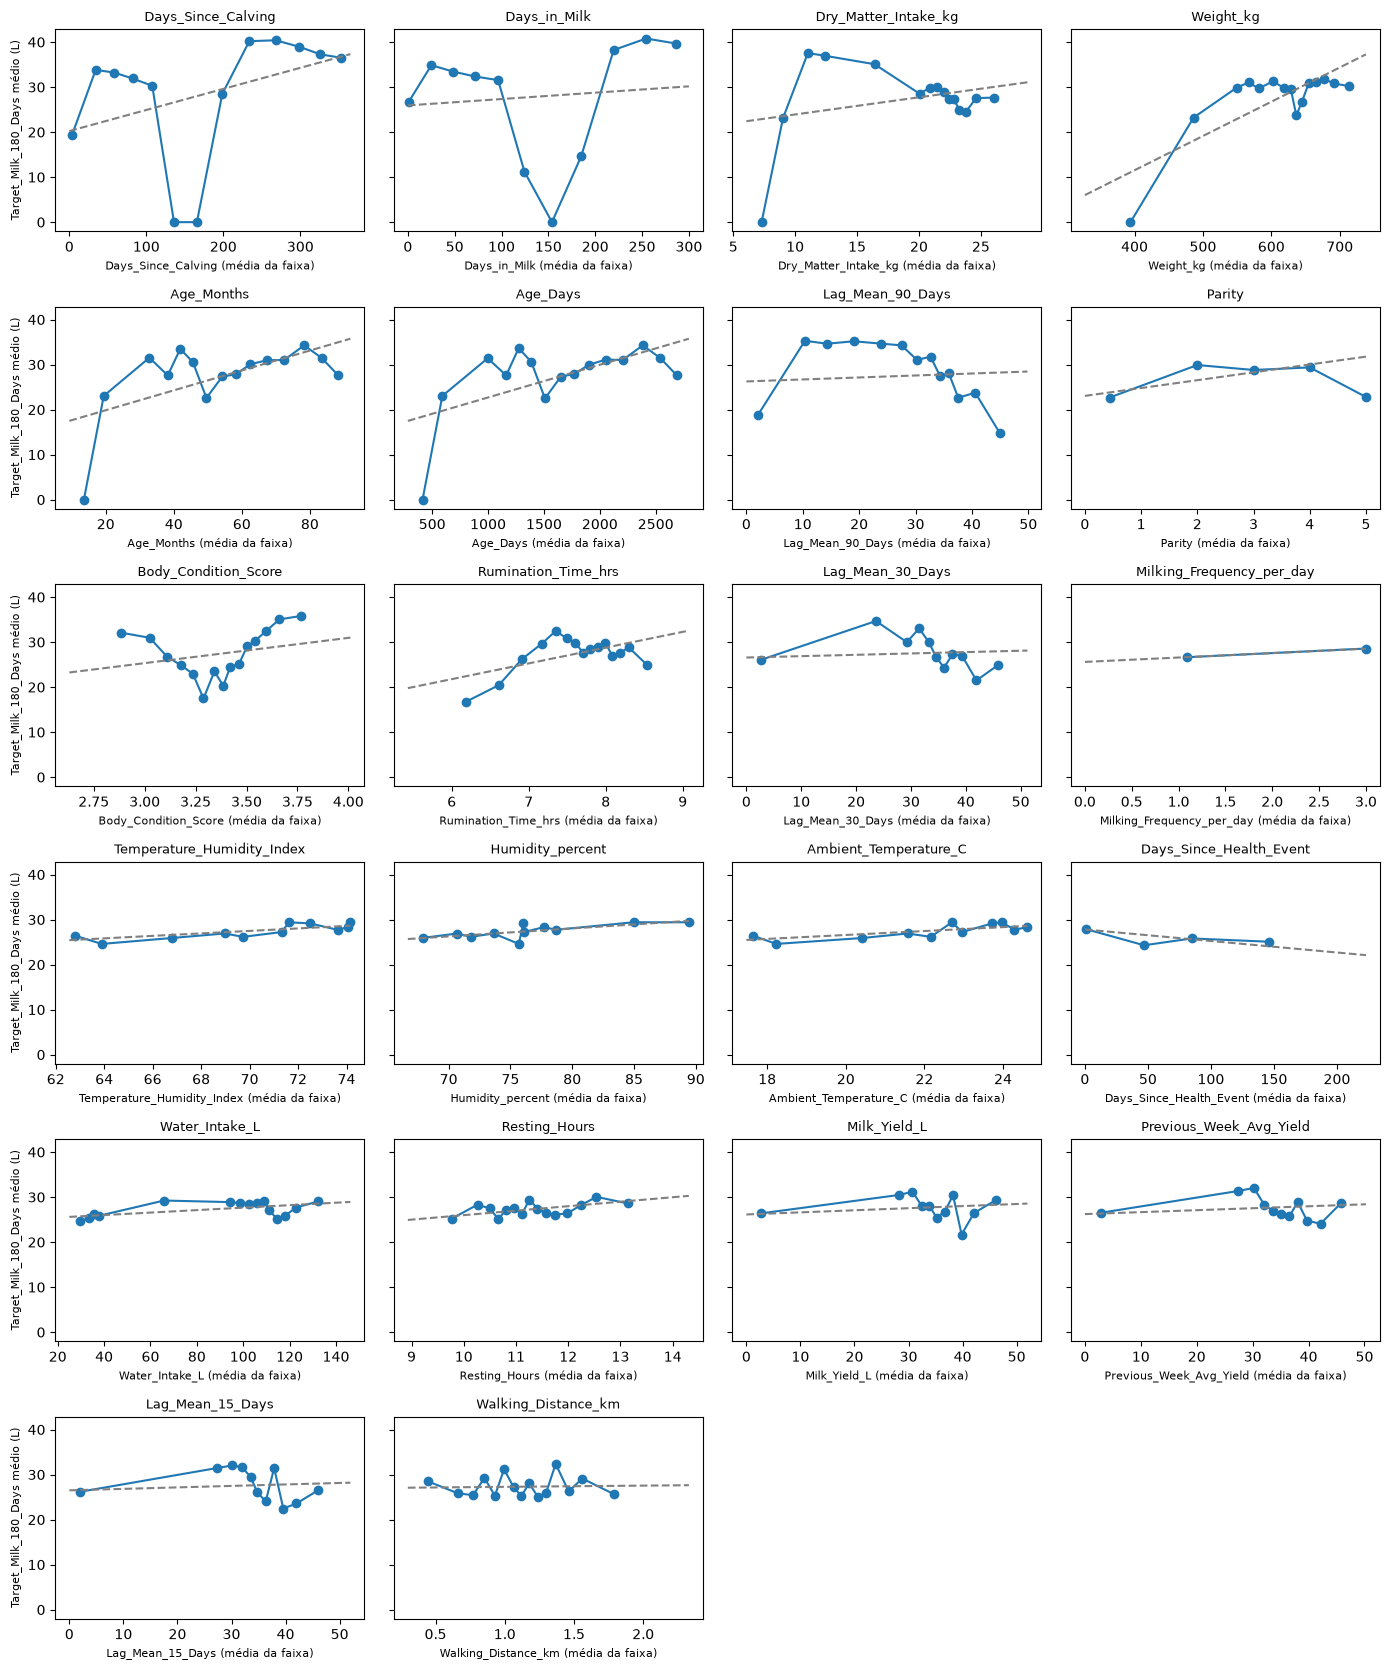

In [35]:
#====================================================================================
#=========================== GRÁFICOS DE MÉDIA POR FAIXA ============================
#====================================================================================

def plot_faixas(ax, col, n=15):
    dados  = df_train[[col, TARGET]].dropna()
    faixas = pd.qcut(dados[col], q=n, duplicates='drop')
    medias = dados.groupby(faixas, observed=True).mean()
    b, a   = np.polyfit(dados[col], dados[TARGET], 1)
    xs     = np.array([dados[col].min(), dados[col].max()])

    ax.plot(medias[col], medias[TARGET], marker='o')
    ax.plot(xs, a + b * xs, linestyle='--', color='gray')
    ax.set_title(col, fontsize=9)
    ax.set_xlabel(f'{col} (média da faixa)', fontsize=8)

cols = tabela['Feature'].tolist()
nlin = ceil(len(cols) / 4)

fig, axes = plt.subplots(nlin, 4, figsize=(14, 2.8 * nlin), sharey=True)
for ax, col in zip(axes.flat, cols):
    plot_faixas(ax, col)

for ax in axes[:, 0]:
    ax.set_ylabel(f'{TARGET} médio (L)', fontsize=8)

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)
    
plt.tight_layout()
plt.show()




<Axes: xlabel='Days_Since_Calving', ylabel='Milk_Yield_L'>

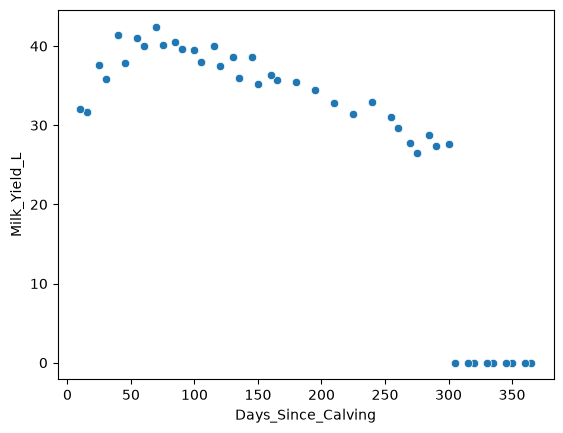

In [55]:
#testando curva de lactação em uma vaca
vaca_prod_dim = df1.loc[(df1['Cattle_ID'] == 'CATTLE_001'), ['Days_Since_Calving', 'Milk_Yield_L']]

sns.scatterplot(vaca_prod_dim, x='Days_Since_Calving', y='Milk_Yield_L')

<Axes: xlabel='Days_Since_Calving', ylabel='Milk_Yield_L'>

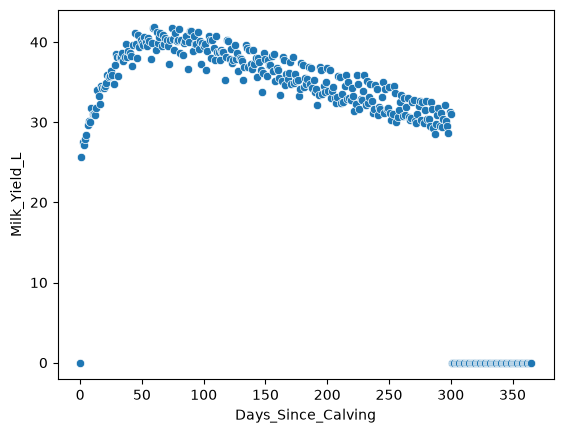

In [54]:
#testando curva de lactação por agrupamento

vaca_agrup_prod_dim = df1.groupby('Days_Since_Calving')['Milk_Yield_L'].mean()

sns.scatterplot(vaca_agrup_prod_dim)

# Resultados

## A tabela

| Feature | Spearman ρ | R² Linear | R² Árvore | Mutual Info | % Outliers | Força | Formato |
|---|---|---|---|---|---|---|---|
| Days_Since_Calving | 0,419 | 0,125 | **0,771** | 0,628 | 0,0 | 🟢 Forte | Curva |
| Days_in_Milk | 0,109 | 0,008 | **0,591** | 0,495 | 0,0 | 🟢 Forte | Curva |
| Dry_Matter_Intake_kg | 0,045 | 0,021 | 0,320 | 0,378 | 0,0 | 🟢 Forte | Curva |
| Weight_kg | 0,212 | 0,156 | 0,256 | 0,270 | 6,0 | 🟢 Forte | Curva |
| Age_Months | 0,235 | 0,093 | 0,244 | 0,333 | 0,0 | 🟡 Moderada | Curva |
| Age_Days | 0,235 | 0,093 | 0,241 | 0,331 | 0,0 | 🟡 Moderada | Curva |
| Lag_Mean_90_Days | 0,069 | 0,002 | 0,191 | 0,368 | 0,0 | 🟡 Moderada | Curva |
| Parity | 0,053 | 0,025 | 0,161 | 0,140 | 19,9 | 🟡 Moderada | Curva |
| Body_Condition_Score | 0,270 | 0,007 | 0,076 | 0,135 | 0,1 | 🔴 Fraca | Sem relação |
| Rumination_Time_hrs | 0,044 | 0,020 | 0,039 | 0,039 | 1,1 | 🔴 Fraca | Sem relação |
| Milk_Yield_L | −0,019 | 0,003 | −0,038 | 0,239 | 0,0 | 🔴 Fraca | Sem relação |
| Temperature_Humidity_Index | 0,109 | 0,005 | −0,012 | 0,000 | 0,0 | 🔴 Fraca | Sem relação |
| Days_Since_Health_Event | −0,086 | 0,005 | −0,010 | 0,000 | 24,5 | 🔴 Fraca | Sem relação |

As outras 9 features (`Lag_Mean_30_Days`, `Lag_Mean_15_Days`, `Previous_Week_Avg_Yield`, `Milking_Frequency_per_day`, `Humidity_percent`, `Ambient_Temperature_C`, `Water_Intake_L`, `Resting_Hours`, `Walking_Distance_km`) também saíram **Fraca / Sem relação**, com R² Máx abaixo de 0,02.

**Leitura geral:** nenhuma feature relevante é reta. Todas as 8 com alguma força são **curvas**, e a reta sozinha nunca explica mais que 16% (Weight_kg).

## O que os gráficos mostram

### 1. O ciclo da vaca: Days_Since_Calving e Days_in_Milk

Os dois gráficos do topo têm o mesmo desenho: o alvo começa médio, **cai até zero** e **volta a subir** até ~40 L. A reta cinza passa no meio e não captura nada disso. Por isso o R² Linear é 0,13 e 0,01, enquanto a árvore chega a 0,77 e 0,59.

A causa é o ciclo produtivo. O intervalo entre partos é de 365 dias (~290 de lactação e ~60 seca), e o alvo é a produção **no dia, 180 dias à frente**:

| Hoje: dias desde o parto | Daqui a 180 dias | Produção no alvo |
|---|---|---|
| 0 (recém-parida) | 180 dias de lactação | média |
| 150 | 330 → **seca** | **zero** |
| 220 | 400 → novo parto, 35 dias de lactação | **alta** (perto do pico) |

O vale em zero do gráfico (entre ~130 e ~170 dias) são exatamente as vacas que estarão secas daqui a 180 dias.

### 2. Weight, Dry_Matter_Intake e Age: a força vem quase toda da primeira faixa

Com o eixo Y igual para todos, fica visível algo que a tabela não mostra: nesses quatro gráficos, **a primeira faixa está em zero** (animais mais leves, mais novos e que comem menos), e a partir da segunda faixa a curva fica **quase plana**, em torno de 25 a 35 L.

Ou seja, essas features separam principalmente **um grupo** de animais (provavelmente os que ainda não estão em lactação ou estão secos) do restante. Entre as vacas adultas, peso e idade quase não mudam o alvo. Vale conferir no notebook quem são os animais dessa primeira faixa antes de interpretar essas features como "quanto mais pesada, mais leite".

### 3. Lag_Mean_90_Days: produção passada alta → produção futura menor

O gráfico mostra um platô em ~35 L e uma **queda** nas faixas mais altas. Vacas que produziram muito nos últimos 90 dias estão perto do pico agora, e daqui a 180 dias estarão no fim da lactação ou secas. É o mesmo ciclo visto de outro ângulo.

### 4. Body_Condition_Score: um U visível, mas fraco

O gráfico mostra um U claro: o alvo é mais baixo para ECC perto de 3,3. Mesmo assim, o R² da árvore é só 0,076. As **médias** das faixas variam, mas dentro de cada faixa as vacas variam muito mais (de 0 a 50 L, por causa do ciclo), então o ECC explica pouco da variação total.

O ECC muda ao longo da lactação (a vaca perde condição no início e recupera no fim), então esse U provavelmente reflete a fase do ciclo, informação que `Days_in_Milk` já traz. É candidata a testar no modelo, sem expectativa alta.

### 5. As fracas de verdade

Clima (THI, temperatura, umidade), água, descanso e caminhada aparecem como **linhas planas** entre 25 e 30 L. A reta, a árvore e a Mutual Information concordam (todas ≈ 0). Isso é coerente com um dataset sintético em que a produção é gerada principalmente pelo ciclo de lactação.

> **Quando a Mutual Information discorda.** `Milk_Yield_L` (MI = 0,24), os `Lag_Mean_15/30` e `Water_Intake_L` têm MI moderada, mas R² da árvore ≈ 0, e os gráficos não mostram forma consistente, só zigue-zague. A estimativa da MI é ruidosa, principalmente com muitos valores repetidos (como os zeros das vacas secas). Quando a MI aponta algo que nem a árvore nem o gráfico confirmam, a feature fica como "a confirmar no modelo", não como forte.

## Validação por vaca × validação comum

Rodando a mesma árvore com `KFold` comum (embaralhado, sem separar por vaca), as notas saem infladas:

| Feature | R² Árvore (KFold comum) | R² Árvore (GroupKFold por vaca) | Efeito |
|---|---|---|---|
| Days_Since_Calving | 0,782 | 0,771 | quase igual |
| Days_in_Milk | 0,600 | 0,591 | quase igual |
| Weight_kg | 0,272 | 0,256 | pequena queda |
| Age_Months | 0,287 | 0,244 | **Forte → Moderada** |
| Lag_Mean_90_Days | 0,254 | 0,191 | **Forte → Moderada** |

As features de **ciclo** quase não mudam: a relação vale igual para qualquer vaca. As que caem mais (`Age`, `Lag_Mean_90_Days`) são as que ajudam a **reconhecer a vaca**: idade e produção média são quase uma "impressão digital" de cada animal. Com KFold comum, a árvore aproveita esse reconhecimento; com GroupKFold, não. A nota por vaca é a honesta.

## Features redundantes

| Par | Correlação (Spearman) | Decisão sugerida |
|---|---|---|
| Age_Days × Age_Months | 1,000 | Mesma informação em unidades diferentes. Manter uma |
| Previous_Week_Avg_Yield × Milk_Yield_L | 0,988 | Quase idênticas. Manter uma |
| Lag_Mean_15_Days × Lag_Mean_30_Days | 0,977 | Manter uma (ou só a de 90 dias, que é a única com força) |
| Ambient_Temperature_C × Temperature_Humidity_Index | 0,972 | Esperado: o THI é calculado a partir da temperatura. Manter uma |
| Water_Intake_L × Milk_Yield_L | 0,956 | O consumo de água acompanha a produção do dia |
| Previous_Week_Avg_Yield × Lag_Mean_15_Days | 0,950 | Mais um par de medidas de produção recente |

Redundância não atrapalha um modelo de árvores na previsão, mas divide a importância entre as features do par e deixa a interpretação confusa. Para modelos lineares, atrapalha também a estabilidade dos coeficientes.

## Conclusões e próximos passos

1. **O alvo é governado pelo ciclo de lactação.** `Days_Since_Calving` e `Days_in_Milk` dominam, e a relação é uma curva com vale em zero.
2. **Nenhuma relação relevante é reta.** Isso favorece modelos de árvores (Random Forest, Gradient Boosting), que no backtesting do projeto já tiveram o menor erro. Um modelo linear só funcionaria com features transformadas (por exemplo, a fase da lactação daqui a 180 dias).
3. **Peso, idade e consumo** separam principalmente um grupo de animais (a primeira faixa, com alvo zero). Conferir quem são antes de interpretar.
4. **Remover redundâncias** antes de modelar: uma de cada par da tabela acima.
5. **Próximo passo:** treinar o modelo com todas as features na validação temporal do projeto e medir a **importância por permutação**. É ela, e não esta tabela, que decide o que fica.


### 5.1.3 Análise Univariada Categóricas

## 5.2 Análise Variável Bivariada

## 5.3 Análise Multivariada

### 5.3.1 Multivariada Numérica

### 5.3.2 Multivariada Categórica